# Claims Fraud Data Analysis

## Data Setup

In [1]:
%pip install pandas numpy matplotlib scikit-learn statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict, GridSearchCV, validation_curve)
from sklearn.linear_model import (LinearRegression, LogisticRegression, LogisticRegressionCV,
                                  RidgeCV, LassoCV, ElasticNetCV)
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import LinearSVC, SVC, SVR
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             log_loss, mean_squared_error, r2_score, roc_auc_score, roc_curve,
                             RocCurveDisplay)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
df = pd.read_csv("insurance_claims.csv")

# Dropping irrelevant variables to the potential models
df = df.drop(columns=["_c39", "policy_number", "insured_zip",
                      "incident_location", "policy_bind_date", "incident_date"])

# Cleaining 
df = df.replace("?", "Unknown")
df = df.fillna("Unknown")

# Changing the year of the car model to the vehicle age
df["vehicle_age"] = 2015 - df["auto_year"]
df = df.drop(columns=["auto_year"])

df["fraud"] = (df["fraud_reported"] == "Y").astype(int)
df = df.drop(columns=["fraud_reported"])

print(df.shape)
df.head()

(1000, 34)


,months_as_customer,age,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_sex,insured_education_level,insured_occupation,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,vehicle_age,fraud
0,328,48,OH,250/500,1000,1406.91,0,MALE,MD,craft-repair,...,2,YES,71610,6510,13020,52080,Saab,92x,11,1
1,228,42,IN,250/500,2000,1197.22,5000000,MALE,MD,machine-op-inspct,...,0,Unknown,5070,780,780,3510,Mercedes,E400,8,1
2,134,29,OH,100/300,2000,1413.14,5000000,FEMALE,PhD,sales,...,3,NO,34650,7700,3850,23100,Dodge,RAM,8,0
3,256,41,IL,250/500,2000,1415.74,6000000,FEMALE,PhD,armed-forces,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,1,1
4,228,44,IL,500/1000,1000,1583.91,6000000,MALE,Associate,sales,...,1,NO,6500,1300,650,4550,Accura,RSX,6,0


In [3]:
# Encoding all categorical variables
encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print(encoded.shape)
encoded.head()

(1000, 145)


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,...,auto_model_Pathfinder,auto_model_RAM,auto_model_RSX,auto_model_Silverado,auto_model_TL,auto_model_Tahoe,auto_model_Ultima,auto_model_Wrangler,auto_model_X5,auto_model_X6
0,328,48,1000,1406.91,0,53300,0,5,1,1,...,0,0,0,0,0,0,0,0,0,0
1,228,42,2000,1197.22,5000000,0,0,8,1,0,...,0,0,0,0,0,0,0,0,0,0
2,134,29,2000,1413.14,5000000,35100,0,7,3,2,...,0,1,0,0,0,0,0,0,0,0
3,256,41,2000,1415.74,6000000,48900,-62400,5,1,1,...,0,0,0,0,0,1,0,0,0,0
4,228,44,1000,1583.91,6000000,66000,-46000,20,1,0,...,0,0,1,0,0,0,0,0,0,0


In [4]:
# Too many variables now, many of which have barely any "1s". 
# If the category has less than 50 claims, I'm changing the value to "other"

for col in df.select_dtypes(include="object").columns:
    counts = df[col].value_counts()
    rare = counts[counts < 50].index
    df[col] = df[col].replace(rare, "Other")

encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# This should reduce the number of variables
print(encoded.shape)
encoded.head()

(1000, 98)


/tmp/ipykernel_7416/3806971926.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,...,auto_make_Dodge,auto_make_Ford,auto_make_Honda,auto_make_Jeep,auto_make_Mercedes,auto_make_Nissan,auto_make_Saab,auto_make_Suburu,auto_make_Toyota,auto_make_Volkswagen
0,328,48,1000,1406.91,0,53300,0,5,1,1,...,0,0,0,0,0,0,1,0,0,0
1,228,42,2000,1197.22,5000000,0,0,8,1,0,...,0,0,0,0,1,0,0,0,0,0
2,134,29,2000,1413.14,5000000,35100,0,7,3,2,...,1,0,0,0,0,0,0,0,0,0
3,256,41,2000,1415.74,6000000,48900,-62400,5,1,1,...,0,0,0,0,0,0,0,0,0,0
4,228,44,1000,1583.91,6000000,66000,-46000,20,1,0,...,0,0,0,0,0,0,0,0,0,0


## Weeks 1-6 

In [5]:
encoded["vehicle_age_sq"] = encoded["vehicle_age"] ** 2

X = encoded.drop(columns="fraud")
y = encoded["fraud"]

# stratify keeps the fraud rate (~25%) the same in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [6]:
# This is slow. After it runs once, paste the printed list into
# kept_features = [...] and skip this cell next time.
Xs_train = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X_train.columns)
logit = LogisticRegression(max_iter=1000)

selected = list(Xs_train.columns)
feature_lists = {}

while len(selected) > 1:
    best_score = 0
    for feature in selected:
        candidate = [f for f in selected if f != feature]
        score = cross_val_score(logit, Xs_train[candidate], y_train, cv=3, scoring="roc_auc").mean()
        if score > best_score:
            best_score, best_candidate = score, candidate
    selected = best_candidate
    feature_lists[len(selected)] = selected.copy()

kept_features = feature_lists[18]
print("18 kept features:", kept_features)

18 kept features: ['umbrella_limit', 'insured_occupation_handlers-cleaners', 'insured_hobbies_bungie-jumping', 'insured_hobbies_camping', 'insured_hobbies_exercise', 'insured_hobbies_golf', 'insured_hobbies_hiking', 'insured_hobbies_kayaking', 'insured_hobbies_movies', 'insured_hobbies_paintball', 'insured_hobbies_reading', 'insured_hobbies_video-games', 'incident_severity_Minor Damage', 'incident_severity_Total Loss', 'incident_severity_Trivial Damage', 'incident_state_NY', 'incident_state_WV', 'auto_make_BMW']


In [7]:
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    encoded[kept_features], y, test_size=0.2, random_state=42, stratify=y)

In [8]:
results = []

def score(name, model):
    model.fit(Xf_train, yf_train)
    pred = model.predict(Xf_test)
    # AUC needs a fraud score: probability if the model has one, otherwise the SVM decision score
    if hasattr(model, "predict_proba"):
        fraud_score = model.predict_proba(Xf_test)[:, 1]
    else:
        fraud_score = model.decision_function(Xf_test)
    results.append({"Model": name,
                    "Test AUC": round(roc_auc_score(yf_test, fraud_score), 3),
                    "Fraud recall": round(recall_score(yf_test, pred), 3),
                    "Accuracy": round(accuracy_score(yf_test, pred), 3)})

In [9]:
from sklearn.metrics import roc_auc_score, recall_score, accuracy_score
score("Logistic regression (18 features)",
      make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))

score("Linear SVM (C=1)",
      make_pipeline(StandardScaler(), LinearSVC(C=1, dual=False, max_iter=5000, random_state=42)))

score("RBF SVM (C=5, gamma=scale)",
      make_pipeline(StandardScaler(), SVC(kernel="rbf", C=5, gamma="scale")))

score("Tuned linear SVM (C=0.01)",
      make_pipeline(StandardScaler(), LinearSVC(C=0.01, dual=False, max_iter=5000, random_state=42)))

score("Tuned RBF SVM (C=0.1, gamma=0.0001)",
      make_pipeline(StandardScaler(), SVC(kernel="rbf", C=0.1, gamma=0.0001)))

score("Tuned decision tree (depth 8, leaf 10)",
      DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=42))

score("Tuned random forest (depth 10, leaf 5)",
      RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5,
                             random_state=42, n_jobs=-1))

print(pd.DataFrame(results).to_string(index=False))

                                 Model  Test AUC  Fraud recall  Accuracy
     Logistic regression (18 features)     0.813         0.449     0.800
                      Linear SVM (C=1)     0.822         0.469     0.800
            RBF SVM (C=5, gamma=scale)     0.774         0.490     0.815
             Tuned linear SVM (C=0.01)     0.820         0.449     0.795
   Tuned RBF SVM (C=0.1, gamma=0.0001)     0.816         0.000     0.755
Tuned decision tree (depth 8, leaf 10)     0.781         0.449     0.790
Tuned random forest (depth 10, leaf 5)     0.819         0.408     0.800


## Week 8: K-Nearest Neighbors

In [10]:
from sklearn.neighbors import KNeighborsClassifier

# Scaling is in the pipeline because KNN uses distance
score("KNN (k=5)",
      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)))

print(pd.DataFrame(results).to_string(index=False))

                                 Model  Test AUC  Fraud recall  Accuracy
     Logistic regression (18 features)     0.813         0.449     0.800
                      Linear SVM (C=1)     0.822         0.469     0.800
            RBF SVM (C=5, gamma=scale)     0.774         0.490     0.815
             Tuned linear SVM (C=0.01)     0.820         0.449     0.795
   Tuned RBF SVM (C=0.1, gamma=0.0001)     0.816         0.000     0.755
Tuned decision tree (depth 8, leaf 10)     0.781         0.449     0.790
Tuned random forest (depth 10, leaf 5)     0.819         0.408     0.800
                             KNN (k=5)     0.703         0.388     0.765


Best k: 17 | CV AUC: 0.719


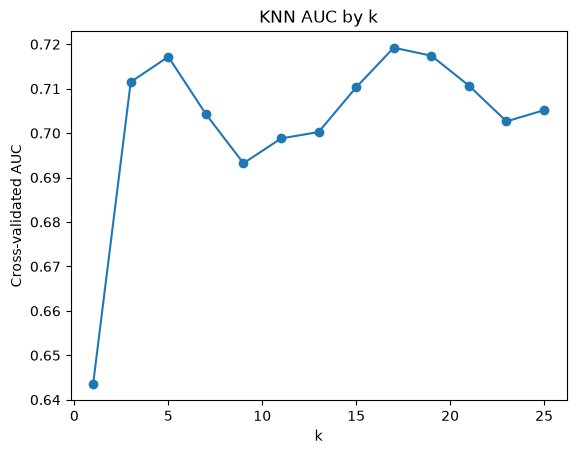

In [11]:
from sklearn.neighbors import KNeighborsClassifier

k_values = range(1, 27, 2)   # 1, 3, 5, ... , 25
cv_auc = []

for k in k_values:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    auc = cross_val_score(knn, Xf_train, yf_train, cv=5, scoring="roc_auc").mean()
    cv_auc.append(auc)

best_k = list(k_values)[cv_auc.index(max(cv_auc))]
print("Best k:", best_k, "| CV AUC:", round(max(cv_auc), 3))

plt.plot(k_values, cv_auc, marker="o")
plt.xlabel("k")
plt.ylabel("Cross-validated AUC")
plt.title("KNN AUC by k")
plt.show()

In [12]:
score("Tuned KNN (k=17)",
      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=17)))

print(pd.DataFrame(results).to_string(index=False))

                                 Model  Test AUC  Fraud recall  Accuracy
     Logistic regression (18 features)     0.813         0.449     0.800
                      Linear SVM (C=1)     0.822         0.469     0.800
            RBF SVM (C=5, gamma=scale)     0.774         0.490     0.815
             Tuned linear SVM (C=0.01)     0.820         0.449     0.795
   Tuned RBF SVM (C=0.1, gamma=0.0001)     0.816         0.000     0.755
Tuned decision tree (depth 8, leaf 10)     0.781         0.449     0.790
Tuned random forest (depth 10, leaf 5)     0.819         0.408     0.800
                             KNN (k=5)     0.703         0.388     0.765
                      Tuned KNN (k=17)     0.659         0.224     0.740


                                 Model  Test AUC  Fraud recall  Accuracy
     Logistic regression (18 features)     0.813         0.449     0.800
                      Linear SVM (C=1)     0.822         0.469     0.800
            RBF SVM (C=5, gamma=scale)     0.774         0.490     0.815
             Tuned linear SVM (C=0.01)     0.820         0.449     0.795
   Tuned RBF SVM (C=0.1, gamma=0.0001)     0.816         0.000     0.755
Tuned decision tree (depth 8, leaf 10)     0.781         0.449     0.790
Tuned random forest (depth 10, leaf 5)     0.819         0.408     0.800
                             KNN (k=5)     0.703         0.388     0.765
                      Tuned KNN (k=17)     0.659         0.224     0.740
          KNN (k=17, 2 PCA components)     0.710         0.306     0.760


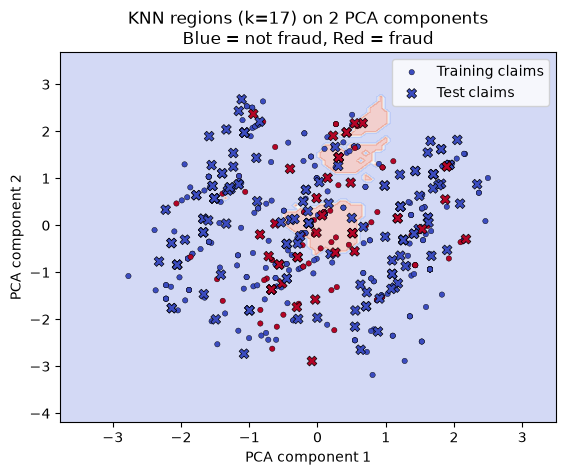

In [13]:
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay

# Scale, then compress the 18 features into 2 (for the picture only)
scaler = StandardScaler()
pca = PCA(n_components=2)
train_2d = pca.fit_transform(scaler.fit_transform(Xf_train))
test_2d = pca.transform(scaler.transform(Xf_test))

# Fitting KNN on the 2 PCA dimensions, using k = 17
knn_2d = KNeighborsClassifier(n_neighbors=17)
knn_2d.fit(train_2d, yf_train)

# Scoring the 2-PCA-component KNN model on the test data
pred_2d = knn_2d.predict(test_2d)
prob_2d = knn_2d.predict_proba(test_2d)[:, 1]

auc_2d = round(roc_auc_score(yf_test, prob_2d), 3)
recall_2d = round(recall_score(yf_test, pred_2d), 3)
acc_2d = round(accuracy_score(yf_test, pred_2d), 3)

# Adding it to my results table
results.append({"Model": "KNN (k=17, 2 PCA components)",
                "Test AUC": auc_2d, "Fraud recall": recall_2d, "Accuracy": acc_2d})
print(pd.DataFrame(results).to_string(index=False))

# Shading the background by what KNN would predict at each spot
DecisionBoundaryDisplay.from_estimator(knn_2d, train_2d, response_method="predict",
                                       cmap="coolwarm", alpha=0.25)

# Drawing the training points and test points, colored by the actual fraud
plt.scatter(train_2d[:, 0], train_2d[:, 1], c=yf_train, cmap="coolwarm",
            marker="o", s=15, edgecolor="k", linewidth=0.3, label="Training claims")
plt.scatter(test_2d[:, 0], test_2d[:, 1], c=yf_test, cmap="coolwarm",
            marker="X", s=50, edgecolor="k", linewidth=0.5, label="Test claims")

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("KNN regions (k=17) on 2 PCA components\nBlue = not fraud, Red = fraud")
plt.legend()
plt.show()

## Week 9: Gradient Boosting

In [14]:
from sklearn.ensemble import GradientBoostingClassifier

score("Gradient Boosting (default)", GradientBoostingClassifier(random_state=42))
print(pd.DataFrame(results).to_string(index=False))

                                 Model  Test AUC  Fraud recall  Accuracy
     Logistic regression (18 features)     0.813         0.449     0.800
                      Linear SVM (C=1)     0.822         0.469     0.800
            RBF SVM (C=5, gamma=scale)     0.774         0.490     0.815
             Tuned linear SVM (C=0.01)     0.820         0.449     0.795
   Tuned RBF SVM (C=0.1, gamma=0.0001)     0.816         0.000     0.755
Tuned decision tree (depth 8, leaf 10)     0.781         0.449     0.790
Tuned random forest (depth 10, leaf 5)     0.819         0.408     0.800
                             KNN (k=5)     0.703         0.388     0.765
                      Tuned KNN (k=17)     0.659         0.224     0.740
          KNN (k=17, 2 PCA components)     0.710         0.306     0.760
           Gradient Boosting (default)     0.802         0.510     0.815


In [15]:
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid={"n_estimators": [50, 100, 200, 300],     # number of trees
                "learning_rate": [0.01, 0.05, 0.1],      # learning rates
                "max_depth": [1, 2, 3]},                 # complexity of each tree
    scoring="roc_auc", cv=5)

gb_grid.fit(Xf_train, yf_train)
print("Best settings:", gb_grid.best_params_, "| CV AUC:", round(gb_grid.best_score_, 3))

Best settings: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300} | CV AUC: 0.825


In [16]:
score("Tuned Gradient Boosting (depth 2, 300 trees, lr 0.1)", gb_grid.best_estimator_)
print(pd.DataFrame(results).to_string(index=False))

                                               Model  Test AUC  Fraud recall  Accuracy
                   Logistic regression (18 features)     0.813         0.449     0.800
                                    Linear SVM (C=1)     0.822         0.469     0.800
                          RBF SVM (C=5, gamma=scale)     0.774         0.490     0.815
                           Tuned linear SVM (C=0.01)     0.820         0.449     0.795
                 Tuned RBF SVM (C=0.1, gamma=0.0001)     0.816         0.000     0.755
              Tuned decision tree (depth 8, leaf 10)     0.781         0.449     0.790
              Tuned random forest (depth 10, leaf 5)     0.819         0.408     0.800
                                           KNN (k=5)     0.703         0.388     0.765
                                    Tuned KNN (k=17)     0.659         0.224     0.740
                        KNN (k=17, 2 PCA components)     0.710         0.306     0.760
                         Gradient Boosting 